# Radargram plotting

DELORES radar line HEnorth FL5 over Henry Ice Rise, with the proposed drill site.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.patches import Rectangle
import geopandas as gpd


In [2]:
# speed of light in ice
v_ice = 168e6;
# Sampling Frequency of DELORES
sampFreq = 250e6;
sampPeriod = 1./sampFreq;
# Ratio of sample number to vertical distance from the surface
sample_to_dist = v_ice * sampPeriod / 2;


## Load the radar data

In [3]:
path = '/Users/jkingslake/Documents/papers/WAIS_readvance_Kingslake/files_from_dell_machine/1/HenryFormation/HENORTH_FL5/FinalRadargramForPublication/HENORTH_FL5_2.ASC'
data = np.loadtxt(path)  

## Load the position data and compute distance along the line and an elevation scale

In [15]:
p_path = '/Users/jkingslake/Documents/papers/WAIS_readvance_Kingslake/files_from_dell_machine/1/HenryFormation/HEnorth_FL5/FinalRadargramForPublication/DBPosFL15.dst'
p = np.loadtxt(p_path)  # shape (7123, 3600)

x = p[:, 2]
y = p[:, 3]
h = p[:, 6]
spacing = np.hypot(x[1:] - x[:-1], y[1:] - y[:-1])
distance = np.insert(np.cumsum(spacing),0, 0)
distance = distance[-1] - distance  # flip so that distance increases from left to right in the radargram
# distance = np.flip(distance)  # flip so that distance increases from left to right in the radargram
elevation_of_peak = h.max()   # useful because sample 0 is at the highest point in the radargram, after the REFLEXW topography correction
vertical_distance_from_sample0 = sample_to_dist * np.arange(data.shape[0])
z = elevation_of_peak - vertical_distance_from_sample0

## Put everything into an xarray

In [16]:
da = xr.DataArray(
    data,
    dims=["z", "distance"],
    coords={"distance": (('distance'), distance/1000), 
            "z": (('z'), z), 
            'x': (('distance'), x), 
            'y': (('distance'), y), 
            'h': (('distance'), h)},
    name="amplitude",
)
da.z.attrs['long_name'] = 'elevation above sea level'
da.z.attrs['units'] = 'm'

da.x.attrs['long_name'] = 'polar stereographic x coordinate'
da.x.attrs['units'] = 'm'

da.y.attrs['long_name'] = 'polar stereographic y coordinate'
da.y.attrs['units'] = 'm'

da.h.attrs['long_name'] = 'surface elevation'
da.h.attrs['units'] = 'm'

da.distance.attrs['long_name'] = 'distance along radar line'
da.distance.attrs['units'] = 'km'

## Flip
For consistency with the way I plotted in past papers, I will redefine the distance coordinate so that it is measured from the other end of the radar line. 

In [14]:
da['distance'] = da['distance'][-1] - da['distance']  
da['distance']

<xarray.DataArray 'distance' (distance: 12946)> Size: 104kB
array([1.294405e+01, 1.294339e+01, 1.294239e+01, ..., 1.564501e-03,
       5.642948e-04, 0.000000e+00], shape=(12946,))
Coordinates:
  * distance  (distance) float64 104kB 12.94 12.94 12.94 ... 0.0005643 0.0
    x         (distance) float64 104kB -9.541e+05 -9.541e+05 ... -9.58e+05
    y         (distance) float64 104kB 5.428e+05 5.428e+05 ... 5.546e+05
    h         (distance) float64 104kB 157.3 157.2 157.2 ... 50.63 50.63 50.55
Attributes:
    long_name:  distance along radar line
    units:      km

In [17]:
da_c = da.coarsen(z=5, distance=5, boundary="trim").mean()

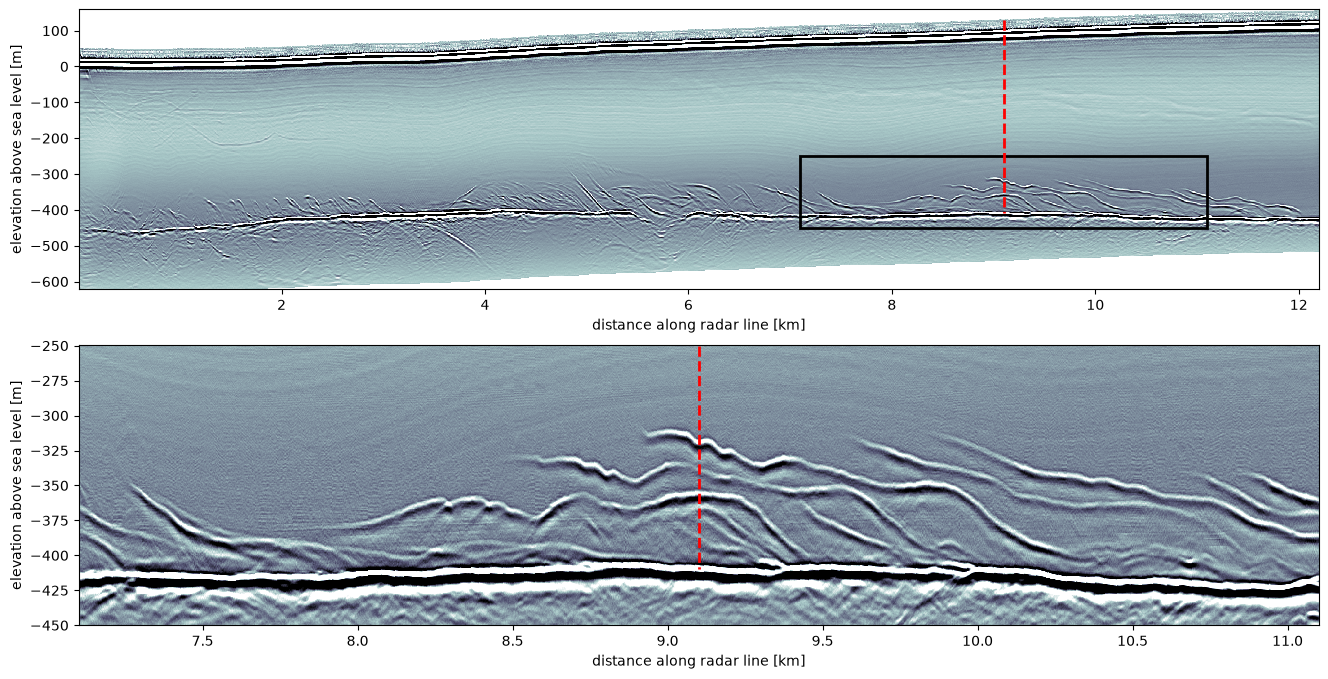

In [46]:

fig, ax = plt.subplots(2,1, figsize = (16, 8),)

drill_distance = 9.1
close_view_bounds = [drill_distance+2, drill_distance-2, -250, -450]

da_c = da_c.where(da_c!=0)

da_c_plotted = da_c.isel(distance = slice(150,-1), z = slice(0,2049))
da_c_plotted.plot(ax = ax[0], vmin = -150, vmax = 50, cmap='bone', add_colorbar=False)

rect = Rectangle(
    (close_view_bounds[0], close_view_bounds[2]),      # bottom-left corner, in data coordinates (distance, z)
    close_view_bounds[1]-close_view_bounds[0],     # extent along x
    close_view_bounds[3]-close_view_bounds[2],     # extent along y
    linewidth=2,
    edgecolor="black",
    facecolor="none",
)
ax[0].add_patch(rect)

ax[0].plot([drill_distance, drill_distance], [130, -410], 'r--', linewidth=2)


da_close = da.sel(distance=slice(close_view_bounds[0], close_view_bounds[1]), z = slice(close_view_bounds[2],close_view_bounds[3]))
da_close.plot(ax = ax[1], vmin = -150, vmax = 50, cmap='bone' , add_colorbar=False)
ax[1].plot([drill_distance, drill_distance], [-250, -410], 'r--', linewidth=2)

drill_x = da_close.sel(distance=drill_distance, method='nearest').x.values
drill_y = da_close.sel(distance=drill_distance, method='nearest').y.values

plt.savefig('HEnorth_FL5_with_1drillsite.png', dpi = 300, bbox_inches='tight'   )

In [45]:
da_c_plotted.distance[0]

<xarray.DataArray 'distance' ()> Size: 8B
array(12.19250134)
Coordinates:
    distance  float64 8B 12.19
    x         float64 8B -9.542e+05
    y         float64 8B 5.431e+05
    h         float64 8B 155.9
Attributes:
    long_name:  distance along radar line
    units:      km

In [20]:
drillsite_gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy([drill_x], [drill_y]), crs="EPSG:3031")
drillsite_gdf.to_file('drillsite_gdf.geojson', driver='GeoJSON')
drillsite_gdf

,geometry
0,POINT (-955191.471 545987.856)


In [47]:
HEnorth_FL5_gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(da_c_plotted.x.values, da_c_plotted.y.values), crs="EPSG:3031")
HEnorth_FL5_gdf.to_file('HEnorth_FL5_gdf.geojson', driver='GeoJSON')

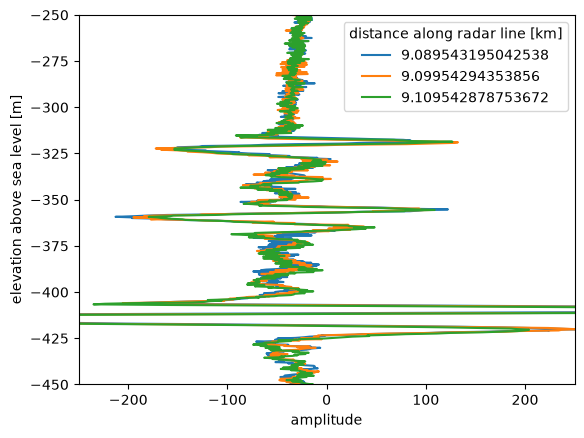

In [302]:
da.sel(distance = drill_distance+np.array([-0.01, 0, 0.01])    , method='nearest').plot.line(y='z', xlim=(-250,250),  ylim = (-450, -250))

In [23]:
segy_file = '/Users/jkingslake/Documents/data/ronne_fieldwork/FieldData_14_15_old/DELORES/BHundelbyProcessing/HENorthdays1-7 final/Day 3/HEnorth_FL12-2/ASCII/HENORTH_FL12-2mig.SGY'

In [32]:
import segyio
import numpy as np
with segyio.open(segy_file, ignore_geometry=True) as f:
    data = segyio.tools.collect(f.trace[:])  # shape: (n_traces, n_samples)
    sample_rate = segyio.tools.dt(f)   # in ms

In [33]:
data

array([[ 0.03125 ,  0.03125 ,  0.03125 , ..., 12.      , 13.      ,
        10.      ],
       [ 0.03125 ,  0.03125 ,  0.03125 , ...,  9.335698,  9.099291,
         8.198581],
       [ 0.03125 ,  0.03125 ,  0.03125 , ...,  8.298746,  7.350627,
         9.896236],
       ...,
       [ 0.03125 ,  0.03125 ,  0.03125 , ..., 13.56692 , 11.56692 ,
        15.015778],
       [ 0.03125 ,  0.03125 ,  0.03125 , ..., 17.199677, 16.039612,
        15.320132],
       [ 0.03125 ,  0.03125 ,  0.03125 , ..., 17.      , 17.      ,
        15.999999]], shape=(6059, 3001), dtype=float32)

In [34]:
sample_rate

4000.0

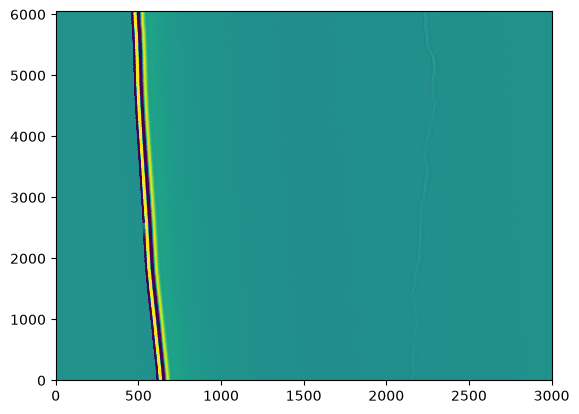

In [36]:
plt.pcolormesh(data)

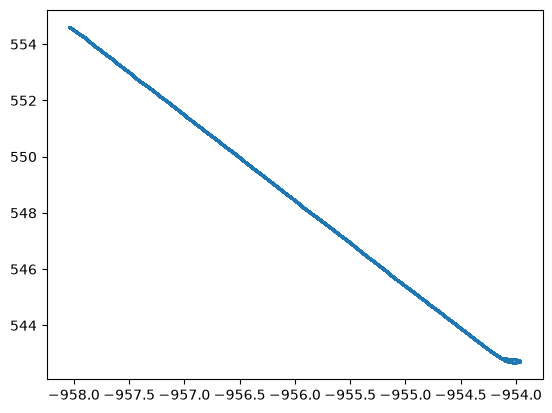

In [32]:
plt.scatter(da_p.x/1000, da_p.y/1000, s=1)

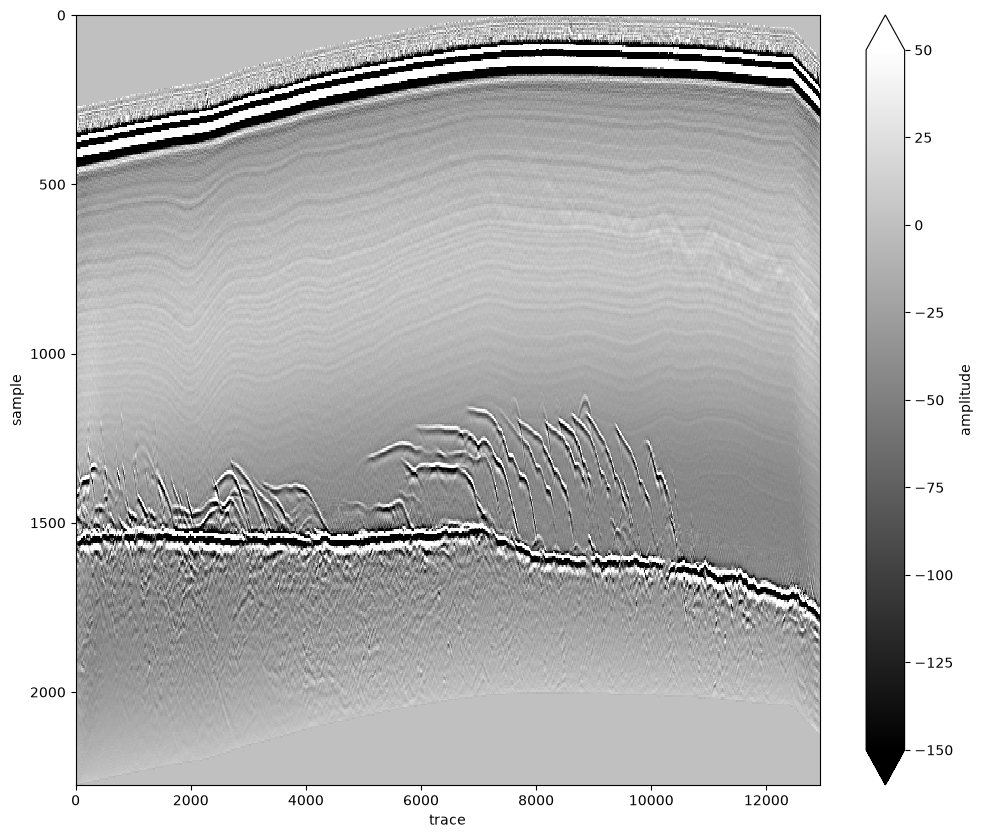

In [91]:
da_c.plot(yincrease = False, cmap='gray', vmin=-150, vmax=50, figsize = (12, 10))

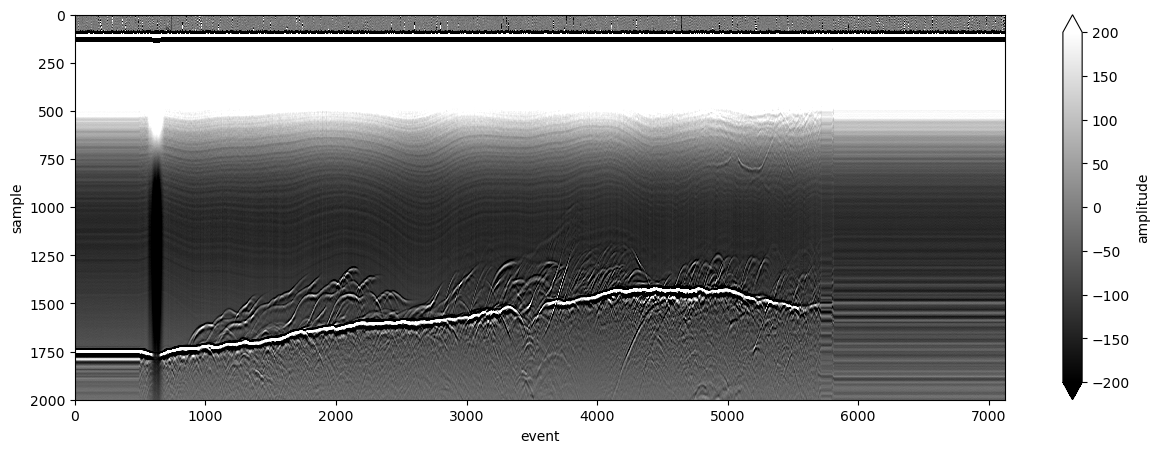

In [32]:
da.plot(x = 'event', y='sample', yincrease = False, cmap = 'gray', figsize = (15, 5), vmin = -200, vmax = 200)


In [91]:
import pandas as pd
import geopandas as gpd
import xarray as xr

p_path = '../FieldData_14_15_old/DELORES/BHundelbyProcessing/HENorthdays1-7 final/Day 7/HEnorth_FL5/HEnorth_FL5Dual_bandpositions.csv'

# Load positions
df = pd.read_csv(p_path, header=None, names=['Latitude', 'Longitude', 'elevation', 'trace'])

# Adjust these to match your actual column names
lon_col, lat_col = 'Longitude', 'Latitude'

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
    crs='EPSG:4326'  # WGS84
)

# Reproject to Universal Polar Stereographic
# South: EPSG:32761 (WGS84 / UPS South)
# North: EPSG:32661 (WGS84 / UPS North)
gdf_ups = gdf.to_crs('EPSG:32761')

gdf_ups['x'] = gdf_ups.geometry.x
gdf_ups['y'] = gdf_ups.geometry.y

x = gdf_ups['x'].values
y = gdf_ups['y'].values
x[~np.isfinite(x)] = np.nan
y[~np.isfinite(y)] = np.nan

# Combine with xarray DataArray (assumes row order in CSV matches event order)
da = da.assign_coords(
    x=('trace', x),
    y=('trace', y),
)

gdf_ups

,Latitude,Longitude,elevation,trace,geometry,x,y
0,-79.921639,-60.362986,157.30,1,POINT (1025032.188 2554692.215),1.025032e+06,2.554692e+06
1,-79.921639,-60.362986,157.30,2,POINT (1025032.188 2554692.215),1.025032e+06,2.554692e+06
2,-79.921639,-60.362986,157.30,3,POINT (1025032.188 2554692.215),1.025032e+06,2.554692e+06
3,-79.921639,-60.362986,157.30,4,POINT (1025032.188 2554692.215),1.025032e+06,2.554692e+06
4,-79.921639,-60.362986,157.30,5,POINT (1025032.188 2554692.214),1.025032e+06,2.554692e+06
...,...,...,...,...,...,...,...
7118,-79.837181,-59.932717,50.56,7119,POINT (1021049.018 2566731.448),1.021049e+06,2.566731e+06
7119,-79.837181,-59.932717,50.56,7120,POINT (1021049.018 2566731.448),1.021049e+06,2.566731e+06
7120,-79.837181,-59.932717,50.56,7121,POINT (1021049.019 2566731.447),1.021049e+06,2.566731e+06
7121,-79.837181,-59.932717,50.56,7122,POINT (1021049.019 2566731.447),1.021049e+06,2.566731e+06


In [83]:
# df = pd.read_csv(p_path, header=None, names=['Latitude', 'Longitude', 'elevation', 'trace'])
gdf

,Latitude,Longitude,elevation,trace,geometry
0,-79.921639,-60.362986,157.30,1,POINT (-60.36299 -79.92164)
1,-79.921639,-60.362986,157.30,2,POINT (-60.36299 -79.92164)
2,-79.921639,-60.362986,157.30,3,POINT (-60.36299 -79.92164)
3,-79.921639,-60.362986,157.30,4,POINT (-60.36299 -79.92164)
4,-79.921639,-60.362986,157.30,5,POINT (-60.36299 -79.92164)
...,...,...,...,...,...
7118,-79.837181,-59.932717,50.56,7119,POINT (-59.93272 -79.83718)
7119,-79.837181,-59.932717,50.56,7120,POINT (-59.93272 -79.83718)
7120,-79.837181,-59.932717,50.56,7121,POINT (-59.93272 -79.83718)
7121,-79.837181,-59.932717,50.56,7122,POINT (-59.93272 -79.83718)


In [59]:
da = da.isel(event=slice(100, -1)  )# Adjust the slice as needed

In [85]:
x

array([nan, nan, nan, ..., nan, nan, nan], shape=(7123,))

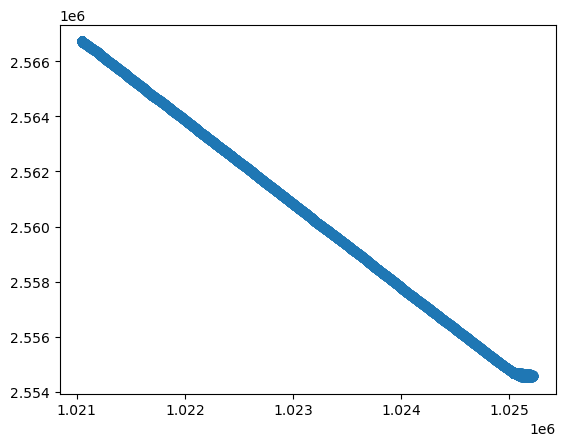

In [92]:
import matplotlib.pyplot as plt
plt.scatter(da.x, da.y)

In [93]:
da

<xarray.DataArray 'amplitude' (trace: 7123, sample: 3600)> Size: 103MB
array([[ 463, -183,  327, ...,    7,    1,    6],
       [  -8,  -10,  -74, ...,    9,    1,    0],
       [ -58,  115,   67, ...,    7,    8,    7],
       ...,
       [ -98, -224, -171, ...,   12,   10,    9],
       [ -11,  -26,  -60, ...,   18,    6,    1],
       [  -3,    4, -104, ...,    9,    7,    9]],
      shape=(7123, 3600), dtype=int32)
Coordinates:
  * trace    (trace) int64 57kB 0 1 2 3 4 5 6 ... 7117 7118 7119 7120 7121 7122
  * sample   (sample) int64 29kB 0 1 2 3 4 5 6 ... 3594 3595 3596 3597 3598 3599
    x        (trace) float64 57kB 1.025e+06 1.025e+06 ... 1.021e+06 1.021e+06
    y        (trace) float64 57kB 2.555e+06 2.555e+06 ... 2.567e+06 2.567e+06

In [94]:
d = np.hypot(da.x[1:] - da.x[:-1], da.y[1:] - da.y[:-1])
d

<xarray.DataArray 'x' (trace: 7121)> Size: 57kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(7121,))
Coordinates:
  * trace    (trace) int64 57kB 1 2 3 4 5 6 7 ... 7116 7117 7118 7119 7120 7121
    x        (trace) float64 57kB 1.025e+06 1.025e+06 ... 1.021e+06 1.021e+06
    y        (trace) float64 57kB 2.555e+06 2.555e+06 ... 2.567e+06 2.567e+06